# Modelo de consumo de energía (eVED_EV.csv)

Calibra el consumo del EV a partir de la telemetría real y estima la capacidad de batería.

- **kWh/km**: regresión robusta de energía total de viaje sobre distancia (ponderada por distancia).
- **Capacidad**: energía por viaje / ΔSOC.
- Gráficos de consumo vs. distancia y vs. velocidad.

Ver `src/consumption_model.py` para la implementación.

In [7]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import consumption_model as cm
from src import data_loading

In [8]:
df = data_loading.load_ev_telemetry()
print('Muestras:', len(df), '| Vehículos EV:', sorted(df['VehId'].unique()), '| Viajes:', df['Trip'].nunique())
trips = cm.aggregate_trips(df)
trips.describe()

Muestras: 476308 | Vehículos EV: [np.int64(10), np.int64(455), np.int64(541)] | Viajes: 491


,VehId,Trip,n_samples,distance_km,energy_kwh,dsoc_pct,speed_mean,gradient_mean
count,504.000000,504.000000,504.000000,504.000000,504.000000,504.000000,504.000000,504.000000
mean,279.236111,1837.652778,945.055556,4.570616,1.511319,4.283295,39.640765,-0.000004
std,219.827064,685.518985,757.567839,3.572852,1.263815,4.152855,12.010262,0.000158
min,10.000000,554.000000,103.000000,0.096176,-0.003282,-0.121956,3.490542,-0.000839
25%,10.000000,1362.250000,397.750000,1.968448,0.577160,1.341461,31.690630,-0.000068
50%,455.000000,1827.500000,749.000000,3.566122,1.156834,3.048775,39.064412,0.000001
75%,455.000000,2297.250000,1210.750000,5.856513,2.111377,5.975609,46.598664,0.000067
max,541.000000,3271.000000,4729.000000,21.301987,7.587408,22.926830,89.431499,0.000647


In [9]:
model = cm.fit(df)
p = model.params
print(f'kWh/km (robusto):        {p.kwh_per_km:.4f}')
print(f'kWh/km (mediana ratios): {p.kwh_per_km_median_ratio:.4f}')
print(f'Capacidad batería:       {p.battery_capacity_kwh:.1f} kWh')
print(f'Viajes usados:           {p.n_trips_used}')
print(f'Dentro de rango físico (0.12-0.30): {p.within_plausible_range}')
print('\nNota: el kWh/km incluye consumo de accesorios (A/C, calefacción) y')
print('ralentí, no solo tracción, por eso puede superar el rango de solo-tracción.')

kWh/km (robusto):        0.3304
kWh/km (mediana ratios): 0.3188
Capacidad batería:       32.7 kWh
Viajes usados:           489
Dentro de rango físico (0.12-0.30): False

Nota: el kWh/km incluye consumo de accesorios (A/C, calefacción) y
ralentí, no solo tracción, por eso puede superar el rango de solo-tracción.


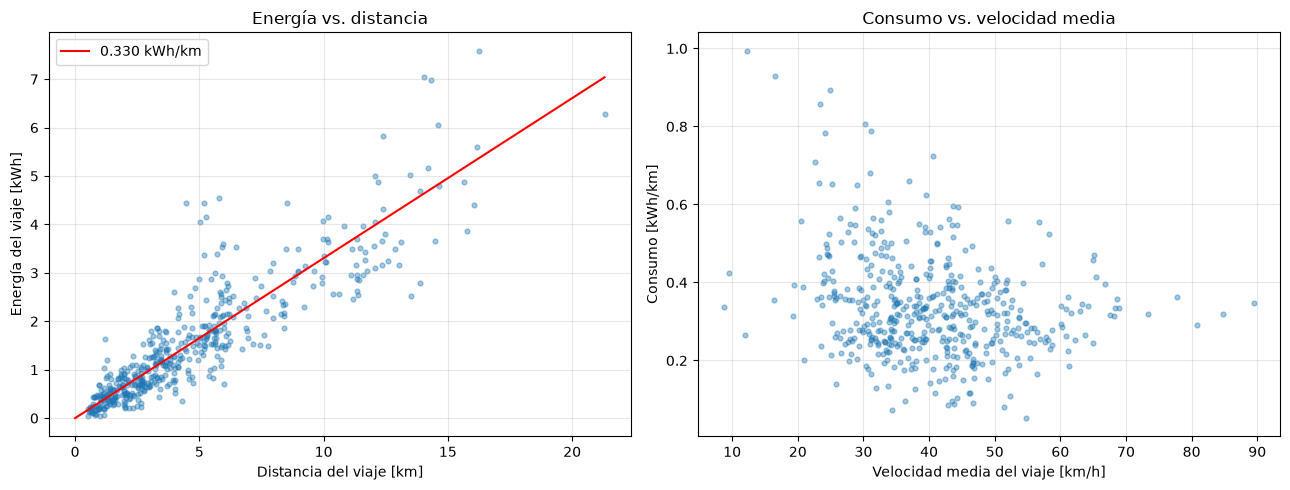

In [10]:
valid = trips[(trips['distance_km'] >= 0.5) & (trips['energy_kwh'] > 0)].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(valid['distance_km'], valid['energy_kwh'], s=12, alpha=0.4)
xs = np.linspace(0, valid['distance_km'].max(), 50)
axes[0].plot(xs, model.kwh_per_km * xs, 'r-', label=f'{model.kwh_per_km:.3f} kWh/km')
axes[0].set_xlabel('Distancia del viaje [km]')
axes[0].set_ylabel('Energía del viaje [kWh]')
axes[0].set_title('Energía vs. distancia')
axes[0].legend(); axes[0].grid(alpha=0.3)

valid['ratio'] = valid['energy_kwh'] / valid['distance_km']
r = valid[valid['ratio'].between(0.05, 1.0)]
axes[1].scatter(r['speed_mean'], r['ratio'], s=12, alpha=0.4)
axes[1].set_xlabel('Velocidad media del viaje [km/h]')
axes[1].set_ylabel('Consumo [kWh/km]')
axes[1].set_title('Consumo vs. velocidad media')
axes[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()

El consumo por km tiende a bajar con la velocidad media (menos tiempo de ralentí por km) y la energía total crece linealmente con la distancia, lo que valida el modelo de un único coeficiente kWh/km usado por el EVRP.